This is a file that consists of one huge cell that contains a class with which one can plot almost everything by simply typing one line with a bunch of keywords setting the options (which things to plot, etc.). Look into our Auswertung to see all plots we found useful, because this notebook doesn't contain them all.

The fits for every temperature (just mode 0 but 8-10 plots for each temperature, this file is only capable of handling modes 0,1,2 currently I think) are not done with this file but instead were vibecoded by my colleague in the file `Temperature_singleplots.ipynb`, I have no idea how his file works and didn't understand the setup of his system. So:
* Take this `Plot_class.jpynb` and modify it (probably ask an AI agent to do it), so its capable of handling more than 3 graphs in one line
* use an AI to explain his code and use that

By creating a class instance, you specify the folder and names of the .csv you want to input (They need to be labeled with the corresponding mode number 0,1,2 or the corresponding temperatur eg. 42 at the end). By only giving a folder, it detects all possible files in it. Then you can use the function classname.makeplot(options) to plot the data of modes 0,1,2. Below, I give examples on how to use the function.

There is a designated temperature class for plotting the stacked temperature runs (only amplitudes no fits) and temperature development. 

## HOW TO USE IT
NOTE: The current code only works with a csv that has one header line and the values in this order: FQ	QX	dQX	QY	dQY	A	dA	phi	dphi T. The temperature T row is optionally recognized. So if your file differs, or you still need to calculate A and phi, then search for and change the function `def load_Data`, `def mask_data` and `def erkenne_saettigung` and every appearance of mask_data accodingly. (I didnt do the loading thing nicely, sorry). 

**If youre done doing the data loading correctly**
use the following line after the cell that specifies all the code to create your classes (create one class for each run):

```python
classname (Messreihenname) = Plot("Dateipfad",plottitle="without temp",filenumbers=[Endnummern der Dateien])
```

change the line 

```python
freqs = np.array([276.0,1815.0,5107.0])  # our experiments resonance freqs
```

to set your roughly determined resonance freqs for the fitting function. 

**The controlling function to create all sorts of plots is:**

```python 
class.makeplot(keywords)
```

In the following, I explain all arguments (all default to None) of it and their effect:
* `whichplots=[filenumbers]` specifies which modes should be plotted. For only one big plot of mode i use =[i], for all modes use =[0,1,2]. Combinations of only two mode are also possible, but then you need to set the argument fitorder to the same values as whichplots. (the reason why fitorder doesnt copy the input of whichplots is that whichplots is also used to specify temperature numbers, that only use fitorder 0)
* `freq_min` and `freq_max` control the displayed (and when fit is activated, automatically all data points for fitting) frequencies. They can either be given a list of the same number of cutoff freqs as specified in whichplots: `freq_min=[100,1500,4900],freq_max=[300,1700,5200]` or just one value, if whichplots is only one big plot: `freq_min=100,freq_max=300`
* `fit=True/None` for activating the fitting function (that automatically displays the eigenfrequency, FHWM, chi2). Those numbers and a bunch of other calculated values are printed below the plot.
* `fitorder=True/[]` if you fit all 0,1,2 modes. If you specified it in whichplots, then you need to specify it here also with the mode numbers given in whichplots (this needs to be done to select the starting values used by scipy for the fit parameters)
* `xy_switch=True/None` together with fit=True to plot the X,Y signal and fittedcurve, it automatically searches the FWHM of X and the Nullstelle of Y and prints them. If fit=None while xy_switch=True, then it only displays the raw X,Y data. 
* `phase=True/None` to just plot the phase (fit=None in this case)
* `residuals=True/None` prints the residuals (it does the fit automatically, so dont give fit=True because it wants to print the fitted curve then aswell, but you need to give `fitorder` for the internal fitting to be done correctly)
* `savefig=True/None` if you are comfortable with your settings, this activates saving in an automatically created ``Plots`` folder. According to the options, the filename is automatically set, so you can recognize the file easily.  


## Temperature fits
Search for `stacked temp` in this file and see there. You use the Plot inherited class Layered_Plot and the layered plot function to do the stacked plots and the layered plot with argument `plot_type='temperature'` for the temp development.
```python
all_numbers=np.arange(42,60,2) 
print(all_numbers) # check if the array is representing all your temperatures
Temp=Layered_Plot("Messungen/PC1/PC1_final_WithTemp/TempFreq",plottitle="temperature run PC1",filenumbers=all_numbers)
Temp.layered_plot(freq_min=248,freq_max=252,fit=None,savefig=None)
``` 
As I said, you need to tweak the code (I think you can just tweak makeplot to not use a figure with all subplots in one line, but instead breaks into more rows if you plot more than three) a bit to do all 8-10 temp fits in one figure, but I forgot how it works (Felix made the temp fits).

Sidenote: There is also the function `save_fig` and `save_multiple_fig` but I think they are broke. What they were supposed to do is to automatically save all desired modes/temps each as one big figure. 

Example:
```python
# setup
Test_PC2=Plot("Messungen/PC2/WithoutTemp/final_ResFreq",plottitle="for PC2 without temp",filenumbers=np.array([0,1,2])) 
# plots all fitted modes
Test_PC2.makeplot(whichplots=[0,1,2],freq_min=None,freq_max=None,fit=True,fitorder=True,savefig=True)
```

In [3]:
import numpy as np
from numpy import exp, sqrt, log, pi

from scipy.optimize import curve_fit
from scipy.stats import chi2
%matplotlib widget
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import re
from pathlib import Path
import os
import csv
import re
from time import perf_counter
from time import sleep


# Plot Class

In [4]:
import sys

from termcolor import colored, cprint

def print_red(text):
    cprint(text,(255,0,0))
def print_green(text):
    cprint(text,(0,255,0))

In [5]:
from decimal import Decimal, ROUND_CEILING, ROUND_HALF_UP, getcontext # Besonders für sig. Runden
import math

def round_to_sigs(val,errVal=None,einheiten=None):
    """
    Funktion zur Rundung eines Fehlers und die Anpassung des Messwertes daran. Diese Funktion wurde etwas umständlicher 
    geschrieben, da python mit Floats und Runden schnell in Probleme rennt. Daher musste hier mit dezimal gearbeitet werden.
    Zudem sollten besonders kleine und große Messwerte in der Dezimalschreibweise geschrieben werden, damit diese auch 
    für Protokolle geiegnet sind.

    Parameter
    ----------
    **val** : float
        Messwert

    **errVal** : float
        Ungenauigkeit des Messwertes

    Return
    ------
    **value_rounded** : str
        Gerundeter Messwert

    **error_rounded** : str
        Gerundete Ungenauigkeit des Messwertes

    **res** : str
        "Messwert \\pm Fehler"
    """
    einheiten_str = einheiten if einheiten is not None else ""
    if errVal is not None:
        # Daten zu Dezimal wechseln, da Floats probleme machen
        val = Decimal(str(val))
        errVal = Decimal(str(errVal))

        exp = int(math.floor(math.log10(float(errVal))))            # Die erste signifikante Stellenposition wird anhand des errVal bestimmt

        if round(float(errVal / (Decimal(10) ** exp))) < 3:         # wenn 1,2,3 erste signifikante Stelle, dann kommt eine zweite Nachkommastellenposition hinzu
            exp -= 1

        scale = Decimal(10) ** exp                                  

        val_round = (val / scale).quantize(Decimal('1'), rounding=ROUND_HALF_UP) * scale            # mit scale wird das Komma so verschoben, dass alle signifikanten Stellen vor dem Komma stehen, und dann alle Nachkommastellen weggerundet werden
        err_round = (errVal / scale).quantize(Decimal('1'), rounding=ROUND_CEILING) * scale

        num = f"\\num{{{val_round}({err_round})}}"
        qty = f"\\qty{{{val_round}({err_round})}}{{{einheiten_str}}}" if einheiten else num

        return float(val_round), float(err_round), num, qty
    else:
        val = Decimal(str(val))
        exp = int(math.floor(math.log10(float(val))))
        if round(float(val / (Decimal(10) ** exp))) < 3:         # wenn 1,2,3 erste signifikante Stelle, dann kommt eine zweite Nachkommastellenposition hinzu
            exp -= 1
        scale = Decimal(10) ** exp   
        val_round = (val / scale).quantize(Decimal('1'), rounding=ROUND_HALF_UP) * scale
        num = f"\\num{{{val_round}}}"
        qty = f"\\qty{{{val_round}}}{{{einheiten_str}}}"if einheiten else num
    return float(val_round), None, num, qty

v_round = np.vectorize(round_to_sigs, otypes=[float, float, object, object], excluded=['einheiten'])

    # wissenschaftliche Notation erstmal vernachlässigen (da häufig Einheiten gewollt sind, die 10^/e Prefixe beinhalten)

In [6]:
def sigma_abweichung(p1, err_p1,p2,err_p2):
    """
    Funktion zum berechnen der Sigma-Abweichugn von zwei Messwerten, oder einem Messwert und einem Literaturwert.
    """
    if err_p1 == 0 and err_p2 == 0:
        raise ValueError("Für die Sigma-Abweichung muss mindestens ein Wert fehlerbehaftet sein!")
    else:
        abweichung=Decimal(str(abs(p1 - p2)/(np.sqrt(err_p1 ** 2+err_p2 ** 2))))

    if abweichung == 0:
        return 0.0, "\\num{0}"
    
    exp = int(math.floor(math.log10(float(abweichung))))
    if round(float(abweichung / (Decimal(10) ** exp))) < 3:         # wenn 1,2,3 erste signifikante Stelle, dann kommt eine zweite Nachkommastellenposition hinzu
        exp -= 1
    scale = Decimal(10) ** exp   
    abweichung_round = (abweichung / scale).quantize(Decimal('1'), rounding=ROUND_CEILING) * scale
    res = f"\\num{{{abweichung_round}}}"

    return float(abweichung_round),res



In [7]:
round_to_sigs(1.234,einheiten=r'hertz')

(1.2, None, '\\num{1.2}', '\\qty{1.2}{hertz}')

In [32]:
# TODO for students: Implement a class DataPlot that plots the measurement data in interactive plots.

# freqs = np.array([249.0, 1650.0, 4850.0]) # PC1
freqs = np.array([276.0,1815.0,5107.0])     # PC2

def load_Data(pathname): 
    path = Path.cwd() / pathname
    # Wir lesen die erste Zeile der CSV, um die Anzahl der Spalten zu ermitteln
    with open(path, 'r', encoding='utf-8') as f_obj:
        first_line = f_obj.readline()
    num_cols = len(first_line.split(','))
    # Prüfen, ob die 10. Spalte (Index 9 für Temperatur T) existiert
    if num_cols >= 10:
        f,QX,dQX,QY,dQY,A,dA,phi,dphi,T = np.loadtxt(path, usecols=(0,1,2,3,4,5,6,7,8,9), delimiter=',', skiprows=1, unpack=True)
    else:
        # Falls keine Temperaturspalte da ist (z.B. bei "WithoutTemp"-Messungen)
        f,QX,dQX,QY,dQY,A,dA,phi,dphi = np.loadtxt(path, usecols=(0,1,2,3,4,5,6,7,8), delimiter=',', skiprows=1, unpack=True)
        # Erstelle ein Dummy-Array für T mit Nullen (gleiche Länge wie f)
        T = np.zeros_like(f)
    return f,QX,dQX,QY,dQY,A,dA,phi,dphi,T

# files: "Grobmessung_i" pathname=Grobmessung, 
class Plot():
    def __init__(self, pathname, plottitle, filenumbers=None): #pathname is single string, e.g. "Messung" when the files are called "Messung_1.csv"
        p = Path(pathname)
        self.filename = p.name  # z. B. "Messung"
        self.pathname = (Path.cwd() / p.parent)
        self.plottitle = plottitle                                              # set supertitle with plottitle 
        self.findfiles(filenumbers)
        self._savefig = False

    def findfiles(self, filenumbers):
        print("Requested files:", filenumbers)
        if filenumbers is None:
            found_files = []
            i = 0
            while Path(f"{self.pathname}/{self.filename}{i}.csv").exists():
                found_files.append(i)
                i += 1
            self._found_files = np.array(found_files)
            print(f"These files were found:{self.pathname}/{self.filename}", found_files)
            print("Set Plot.makeplot(whichplots=array) accordingly, with array consisting of desired file endings")
        elif filenumbers.any():
            self._found_files = np.array([num for num in filenumbers if Path(f"{self.pathname}/{self.filename}{num}.csv").exists()])
            print("Of the given files, these were found:", self._found_files)
            if np.array_equal(self._found_files, filenumbers):
                print(f"Your entry was correct, all given files were found.")
            else:
                print(f"Your entry was false, check again. Only {self._found_files} of the requested files were found.")

    def print_messages(self, whichplots, fitorder):
        if whichplots is None:
            self._curves = self._found_files
            self._curvesnumber = len(self._found_files)
            if self._savefig is False:
                print(f"All correct files: {self._curves} are plotted")
        else: 
            self._curves = np.array(whichplots)
            self._curvesnumber = len(self._curves)
            if self._savefig is False:
                print("Only the chosen plots are shown:", whichplots)
        if fitorder is None:
            self.fitorder = np.array([0, 0, 0])
        else:
            self.fitorder = np.array([0, 1, 2])
        
    def makeplot(self, freq_min=None, freq_max=None, fit=None, fitorder=None, whichplots=None, xy_switch=None,phase=None,residuals=None,savefig=None):
        self.print_messages(whichplots, fitorder)
        if self._curvesnumber > 1:
            multiple=True
        else:
            multiple=None

        plt.close('all')
        
        kwargs = {}
        if phase is not None or residuals is not None:
            figsize_y=3
        else:
            figsize_y=5
        if multiple is not None:
            kwargs['figsize'] = [4 * self._curvesnumber, figsize_y]
            filename_ending=''
        elif multiple is None:
            kwargs['figsize']=[6,8]
            filename_ending=f'{self._curves[0]}'
        if fit is None and xy_switch is None and phase is None and residuals is None:
            plottitle_prefix='resonance'
        elif fit is not None and xy_switch is None:
            plottitle_prefix='fitted resonance'
        elif xy_switch is not None:
            plottitle_prefix='X and Y'
        elif phase is not None:
            plottitle_prefix='phase'
        elif residuals is not None:
            plottitle_prefix='residual'

        fig, axes = plt.subplots(1, self._curvesnumber,squeeze=False, **kwargs)
        plottitle=", "+self.plottitle
        if multiple is not None:
            fig.suptitle(f'{plottitle_prefix} curves{plottitle}')
            subplottitle=f'order'
            plottitle=f''
        else:
            subplottitle=f'{plottitle_prefix} curve order'

        for index, ax in enumerate(axes.flatten()):
            f_min = freq_min[index] if isinstance(freq_min, (list, np.ndarray)) else freq_min
            f_max = freq_max[index] if isinstance(freq_max, (list, np.ndarray)) else freq_max
            if fit:
                if index < 3:
                    ax.set_title(f'{subplottitle} {self._curves[index]}{plottitle}')      # if fit = True
                else:
                    ax.set_title(f'{subplottitle} 0 at temperature {self._curves[index]}°C')             # if fit = True and temperatures
                self.makesubplot(ax, self._curves[index],f_min,f_max,fit,xy_switch,phase)
                self.fitonecurve(ax, index, self.fitorder[self._curves[index]],f_min,f_max,xy_switch,residuals)   
            elif residuals is None:                                                                     # if fit = None and res = None
                ax.set_title(f'{subplottitle} {self._curves[index]}{plottitle}')          
                self.makesubplot(ax, self._curves[index],f_min,f_max,fit,xy_switch,phase)
            elif residuals is not None:                                                                 # if fit = None and res = True
                ax.set_title(f'{subplottitle} {self._curves[index]}{plottitle}')
                self.fitonecurve(ax, index, self.fitorder[self._curves[index]],f_min,f_max,xy_switch,residuals)
            if multiple is not None and phase is None and residuals is None:
                handles, labels = axes.flat[0].get_legend_handles_labels()
                fig.legend(
                    handles, labels,
                    loc="upper center", bbox_to_anchor=(0.5, 0.92),     # loc nimmt obere upper center als aufhängungspunkt der legendenbox und bbox setzt sie mit (,) relativ zum Koordinatensystem
                    ncol=6, fontsize=10
                )
            elif multiple is None or phase is not None or residuals is not None:
                ax.legend()

        fig.subplots_adjust(
            hspace=0.48, wspace=0.25,
            top=0.78, bottom=0.35
        )
        # fig.subplots_adjust(
        #             hspace=0.48, wspace=0.25,
        #             top=0.78, bottom=0.36
        #         )
        # fig.tight_layout()
        # Falls der Plot angezeigt werden soll
        if self._savefig is False:

            if savefig is not None:
                folder = f"{self.pathname}/Plots" 
                os.makedirs(folder, exist_ok=True)
                if fit is not None:
                    prefix = 'Fit_'
                else:
                    prefix = 'Plot_'
                if xy_switch is not None:
                    prefix=prefix+"xy_" 
                elif phase is not None:
                    prefix=prefix+"phase_" 
                if residuals is not None:
                    prefix=prefix+"residuals_"
                    print("Choose a plot to save.")   
                fig.savefig(f'{folder}/{prefix}_{self.filename}{filename_ending}.png', format="png", bbox_inches='tight')
                return None
            plt.show()
            return None
        # Falls er NICHT angezeigt werden soll (z. B. beim Speichern):
        # Wir schließen die Figure für Matplotlib, geben sie aber als Objekt zurück,
        # damit savefig() sie noch speichern kann.
        plt.close(fig)
        return fig
    
    def erkenne_saettigung(self, werte):
        MIN_PLATEAU_LAENGE = 5
        PLATEAU_TOLERANZ=1e-4
        """Hilfsmethode zur Erkennung von Sättigungsplateaus."""
        werte = np.asarray(werte, dtype=float)
        maske = np.zeros(len(werte), dtype=bool)
        if len(werte) == 0:
            return maske
            
        maximum = np.max(werte)
        toleranz = max(1e-10, PLATEAU_TOLERANZ * np.ptp(werte))
        
        nahe_maximum = np.abs(werte - maximum) <= toleranz
        kandidaten = np.flatnonzero(nahe_maximum)
        
        if len(kandidaten) == 0:
            return maske

        bloecke = np.split(
            kandidaten,
            np.flatnonzero(np.diff(kandidaten) != 1) + 1
        )

        for block in bloecke:
            if len(block) >= MIN_PLATEAU_LAENGE:
                maske[block] = True

        return maske
    
    def mask_Data(self, index, freq_min, freq_max):
        # 1. Originaldaten laden
        raw_data = load_Data(f"{self.pathname}/{self.filename}{index}.csv")
        f = raw_data[0]
        QX = raw_data[1]
        QY = raw_data[3]

        # 2. Standard-Maske (Frequenzbereich + dA != 0)
        range_mask = np.ones_like(f, dtype=bool)
        if freq_min is not None:
            range_mask &= (f >= freq_min)   # alles kleiner als f_min wird auf False gesetzt, &= ist UND+setzte range_mask dann auf das, ist range_mask UND die klammer bedingung true, dann range mask = True
        if freq_max is not None:
            range_mask &= (f <= freq_max)   # alles größer wird auf False gesetzt

        # 3. Sättigung erkennen
        saett_x = self.erkenne_saettigung(QX)
        saett_y = self.erkenne_saettigung(QY)
        saettigung = saett_x | saett_y

        # Fit-Maske (nur ungesättigte Punkte im Bereich) & Sättigungs-Maske
        fit_mask = range_mask & ~saettigung
        sat_mask = range_mask & saettigung

        # Standard-Daten für den Bereich maskieren (Index 0 bis 9 bleiben voll intakt!)
        masked_data = [arr[range_mask] for arr in raw_data]

        # Normierung auf A_max (wie gehabt)
        if len(masked_data[5]) > 0:
            A_max = np.max(masked_data[5])
            if A_max != 0:
                for i in [1, 2, 3, 4, 5, 6]:
                    masked_data[i] = masked_data[i] / A_max
        
        # 4. Die beiden neuen Frequenz-Arrays und Amplituden für Fit und Sättigung erzeugen
        fitf = raw_data[0][fit_mask]
        fitsf = raw_data[0][sat_mask]
        
        # WICHTIG: Auch hier durch A_max teilen, damit sie auf A/A_max normiert sind!
        if A_max != 0:
            fit_A = raw_data[5][fit_mask] / A_max
            d_fit_A = raw_data[6][fit_mask] / A_max
            fit_sA = raw_data[5][sat_mask] / A_max
            d_fit_sA = raw_data[6][sat_mask] / A_max
        else:
            fit_A = raw_data[5][fit_mask]
            d_fit_A = raw_data[6][fit_mask]
            fit_sA = raw_data[5][sat_mask]
            d_fit_sA = raw_data[6][sat_mask]

        # 5. Ans Ende des Tupels anhängen
        masked_data.append(fitf)      # Index 10
        masked_data.append(fitsf)     # Index 11
        masked_data.append(fit_A)     # Index 12
        masked_data.append(d_fit_A)   # Index 13
        masked_data.append(fit_sA)    # Index 14
        masked_data.append(d_fit_sA)  # Index 15
        masked_data.append(fit_mask)
        masked_data.append(sat_mask)

        return tuple(masked_data)
    

    def makesubplot(self, ax, index,freq_min,freq_max,fit,xy_switch,phase):
        f, QX, dQX, QY, dQY, A, dA, phi, dphi, T,fit_f,fit_sf,fit_A,d_fit_A,fit_sA,d_fit_sA,fit_mask,sat_mask = self.mask_Data(index,freq_min,freq_max)
        if xy_switch is None and phase is None:
            if len(fit_sf)==0:
                ax.errorbar(f, A, yerr=dA,color='C0', elinewidth=0.5, capsize=0, ecolor='black', marker=".", markersize=2, linestyle='none', label='$A$ data points')
                
            elif len(fit_sf) > 0:
                ax.errorbar(fit_f, fit_A, yerr=d_fit_A,color='C0', elinewidth=0.5, capsize=0, ecolor='black', marker=".", markersize=2, linestyle='none', label='$A$ data used for fit')
                ax.errorbar(fit_sf, fit_sA, yerr=d_fit_sA,color='0.65', elinewidth=0.5, capsize=0, ecolor='black', marker=".", markersize=2, linestyle='none', label='$A$ of fit-excluded(saturated) data')
            ax.set_ylabel(r'$A/A_{\mathrm{max}}$',fontsize='large')
        elif xy_switch is not None:
            # ax.errorbar(f, A, yerr=dA, elinewidth=0.5, capsize=0, ecolor='black', marker=".", markersize=2, linestyle='none', label='$A$')
            # X Nulldurchgang bestimmen:
            ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))
            idx_null = np.argmin(np.abs(QX))
            stepsize=f[1]-f[0]
            f_0_R,df_0_R,_,latexf_0_R=round_to_sigs(f[idx_null],stepsize,r'\hertz')
            print(rf"\nu_R aus Nulldurchgang = {latexf_0_R}")
            ax.text(
                0.5, -0.33,
                rf'$\nu_{{{self._curves[index]},X}} = {f_0_R}\pm{df_0_R}$ Hz',
                transform=ax.transAxes,
                fontsize=10, color="red", va="top",ha='center'
            )
            ax.errorbar(fit_f, QX[fit_mask], yerr=dQX[fit_mask],color="red", elinewidth=0.5, capsize=0, ecolor='black', marker=".", markersize=2, linestyle='none', label='$X$ signal')
            ax.errorbar(fit_sf, QX[sat_mask], yerr=dQX[sat_mask],color="0.65", elinewidth=0.5, capsize=0, ecolor='black', marker=".", markersize=2, linestyle='none', label='satured X,Y signal')
            ax.errorbar(fit_f, QY[fit_mask], yerr=dQY[fit_mask], color="green",elinewidth=0.5, capsize=0, ecolor='black', marker=".", markersize=2, linestyle='none', label='$Y$ signal')
            ax.errorbar(fit_sf, QY[sat_mask], yerr=dQX[sat_mask],color="0.65", elinewidth=0.5, capsize=0, ecolor='black', marker=".", markersize=2, linestyle='none')

            ax.set_ylabel(r'$A/A_{\mathrm{max}}$',fontsize='large')
        elif phase is not None:
            ax.errorbar(f, phi, yerr=dphi,color="black", elinewidth=0.5, capsize=0, ecolor='black', marker=".", markersize=2, linestyle='none', label=r'phase $\phi$')
            ax.set_ylabel(r'$\phi$ [rad]',fontsize='large')
        ax.set_xlabel(r'frequency [Hz]')
        

    def fitonecurve(self, ax, index,fitorder,freq_min,freq_max,xy_switch,residuals):
        f, _, _, QY, _, A, dA, _, _, _,fit_f,_,fit_A,d_fit_A,_,_,_,_= self.mask_Data(self._curves[index],freq_min,freq_max)
        w_0_n_start = 2 * np.pi * freqs[fitorder]
        gamma_start = 2 * np.pi * 0.5
        y_0_start=np.min(A)
        f_0_start = (np.max(A) - y_0_start) * gamma_start * w_0_n_start
        try:
            popt, pcov = curve_fit(
                self.lorentzcurve, fit_f, fit_A, 
                p0=[f_0_start, w_0_n_start, gamma_start, y_0_start], 
                sigma=d_fit_A, absolute_sigma=True, bounds=(0, np.inf), maxfev=1000
            )
            perr = np.sqrt(np.diag(pcov))
            
            # Einzelne Parameter sauber runden und printen
            x_f_0, dx_f_0, _, latex_f_0 = round_to_sigs(popt[0], perr[0], r'\volt')
            f_n, df_n, _, latex_nu = round_to_sigs(popt[1]/(2*np.pi), perr[1]/(2*np.pi), r'\hertz')
            g,dg, _, latex_g = round_to_sigs(popt[2], perr[2], r'\rad\per\s')
            x_y0, dx_y0, _, latex_y0 = round_to_sigs(popt[3], perr[3], r'\volt')
            self._f_n=f_n

            Q=popt[1]/g
            dQ=Q*np.sqrt((perr[1]/popt[1])**2+(dg/g)**2)
            Q,dQ,_,latexQ=round_to_sigs(Q,dQ,'')

            w_R=np.sqrt((f_n*2*np.pi)**2-g**2/2)
            dw_R=np.sqrt(2)*np.sqrt((dg**2*g**2 + 4*(df_n*2*np.pi)**2*(f_n*2*np.pi)**2)/(-g**2 + 2*(f_n*2*np.pi)**2))/2
            f_R,df_R,_,latexf_R=round_to_sigs(w_R/(2*np.pi),dw_R/(2*np.pi),r'\hertz')
            print("--- Fit-Ergebnisse ---")
            print(rf" f_0 = {latex_f_0}")
            print(rf"\nu_{{0_{self._curves[index]}}} = {latex_nu}")
            print(rf"\nu_{{R_{self._curves[index]}}} = {latexf_R }")
            print(rf"\gamma = {latex_g}")
            print(rf"y_0 = {latex_y0}")
            print(f"Q ={latexQ}")

            # Erstelle ein feines Evaluations-Array für den Fit
            stepsize=f[1]-f[0]
            f_fine=np.linspace(np.min(f),np.max(f),num=500)
            fit_fine = self.lorentzcurve(f_fine, *popt)
            idx_max = np.argmax(fit_fine)
            # 2. Halbe Maximalhöhe berechnen
            y_max = fit_fine[idx_max]
            y_min = np.min(fit_fine) # oder y_0
            y_half = y_min + (y_max - y_min) / 2

            # 3. Linke Seite: Suche vom Anfang bis zum Peak-Maximum
            idx_left = np.argmin(np.abs(fit_fine[:idx_max] - y_half))
            
            # 4. Rechte Seite: Suche vom Peak-Maximum bis zum Ende
            # (Wichtig: Wir müssen idx_max auf den Index draufrechnen, da das Slice bei 0 startet)
            idx_right = idx_max + np.argmin(np.abs(fit_fine[idx_max:] - y_half))

            # X-Werte und FWHM bestimmen
            f_left = f_fine[idx_left]
            f_right = f_fine[idx_right]
            fhwm_graf,dfhwm_graf,_,latex_fwhm_graf = round_to_sigs(f_right - f_left,np.sqrt(2)*stepsize,einheiten=r'\hertz') 

            Q_graf=np.sqrt(3)*f_R/fhwm_graf
            dQ_graf=Q_graf*np.sqrt(df_R**2/f_R**2+dfhwm_graf**2/fhwm_graf**2)
            Q_graf,dQ_graf,_,latex_Q_graf=round_to_sigs(Q_graf,dQ_graf,'')
            print(rf"Q_{{\text{{graf}}}}={latex_Q_graf}")
            sigma_Q=sigma_abweichung(Q,dQ,Q_graf,dQ_graf)[-1]
            print(rf"S[\sigma]={sigma_Q}")

            FHWM_calc=np.sqrt(3)*f_R/Q
            d_FHWM_calc=FHWM_calc*np.sqrt(df_R**2/f_R**2+dQ**2/Q**2)
            FHWM_calc,d_FHWM_calc,_,latex_FWHM_calc=round_to_sigs(FHWM_calc,d_FHWM_calc,r'\hertz')
            if residuals is None and xy_switch is None:
                ax.hlines(y=y_half, xmin=f_left, xmax=f_right, color='blue', linestyle='-',label=r'FHWM')
                ax.vlines([f_left, f_right], ymin=y_min, ymax=y_half,color="blue", linestyle="dotted", linewidth=0.9)
                ax.text(
                    0.5, -0.33,
                    rf'FHWM$={FHWM_calc}\pm${d_FHWM_calc} Hz',
                    transform=ax.transAxes,
                    fontsize=10, color="blue", va="top",ha="center",
                )

            elif xy_switch is not None:
                # Erstelle ein feines Evaluations-Array für den Fit
                idx_max = np.argmax(QY)
                # 2. Halbe Maximalhöhe berechnen
                y_max = QY[idx_max]
                y_min = np.min(QY) # oder y_0
                y_half = y_min + (y_max - y_min) / 2
    
                # 3. Linke Seite: Suche vom Anfang bis zum Peak-Maximum
                idx_left = np.argmin(np.abs(QY[:idx_max] - y_half))
                
                # 4. Rechte Seite: Suche vom Peak-Maximum bis zum Ende
                # (Wichtig: Wir müssen idx_max auf den Index draufrechnen, da das Slice bei 0 startet)
                idx_right = idx_max + np.argmin(np.abs(QY[idx_max:] - y_half))
    
                # X-Werte und FWHM bestimmen
                f_left = f[idx_left]
                f_right = f[idx_right]
                fhwm_qy_graf,dfhwm_qy_graf,_,latex_qy_fwhm_graf = round_to_sigs(f_right - f_left,stepsize,einheiten=r'\hertz')
                Q_qy_graf=f_R/fhwm_qy_graf
                dQ_qy_graf=Q_qy_graf*np.sqrt(df_R**2/f_R**2+dfhwm_qy_graf**2/fhwm_qy_graf**2)
                Q_qy_graf,dQ_qy_graf,_,latex_Q_qy_graf=round_to_sigs(Q_qy_graf,dQ_qy_graf,'')

                print(rf"Q_{{Y,\text{{ graf}}}}={latex_Q_qy_graf}")
                sigma_Q_Y=sigma_abweichung(Q_qy_graf,dQ_qy_graf,Q,dQ)[-1]
                print(rf"S_Y[\sigma]={sigma_Q_Y}\sigma")

                ax.hlines(y=y_half, xmin=f_left, xmax=f_right, color='blue', linestyle='-',label=r'$\mathrm{FHWM}_Y$')
                ax.vlines([f_left, f_right], ymin=y_min, ymax=y_half,color="blue", linestyle="dotted", linewidth=0.9)

            sigma_FHWM=sigma_abweichung(FHWM_calc,d_FHWM_calc,fhwm_graf,0)[-1]
            print(stepsize)
            print(f"FHWM_graf={latex_fwhm_graf}")
            print(f"FHWM_calc={latex_FWHM_calc}")
            print(rf"S[\sigma]={sigma_FHWM}\sigma")
    
            if residuals is None:
                x = np.linspace(f[0], f[-1], num=500)
                ax.plot(x, self.lorentzcurve(x, *popt),color=f"C1",label='Lorentzian fit')
                ax.axvline(f_n, linestyle='dashed', color='red',label=r'resonance frequency $\nu_n$')
                ax.text(
                    0.5, -0.23,
                    rf'$\nu_{self._curves[index]} = {f_n}\pm{df_n}$ Hz',
                    transform=ax.transAxes,
                    fontsize=10, color="red", va="top",ha='center'
                )
            else:
                res=(fit_A-self.lorentzcurve(fit_f,*popt))/d_fit_A
                ax.errorbar(fit_f, res, color="grey", elinewidth=0.5, capsize=0, ecolor='black', marker=".", markersize=2, linestyle='none', label='residuals')
                ax.set_ylabel(r'residuals')                
                ax.set_xlabel(r'frequency [Hz]')
                ax.grid(True)
            chisquare,_,_,latexchi=round_to_sigs(np.sum(((self.lorentzcurve(fit_f,*popt)-fit_A)**2/d_fit_A**2)))
            N=len(fit_f)
            p=len(popt)
            dof=N-p #degrees of freedom
            print("------")
            print("Datenpunkte N =",N)
            print("Parameterzahl =",p)
            print(f"\\mathrm{{dof}} = {dof}")

            chisquare_red,_,_,latexchired=round_to_sigs(chisquare/dof)
            print(rf"\chi_2 = {latexchi}")
            print(rf"\mathrm{{red}} \chi_2 = {latexchired}")
            prob=round((1-chi2.cdf(chisquare,dof))*100,4)
            print(rf"Fitwahrscheinlichkeit p = \qty{{{prob}}}{{\\percent}}")
            self.find_peaks(self._curves[index],freq_min,freq_max)
            if xy_switch is None:
                ax.text(
                    0.5, -0.43,
                    rf'$\chi^2={chisquare}$    '
                    rf'$\chi^2_{{red}}={chisquare_red}$    '
                    rf'$p={prob}$',
                    transform=ax.transAxes,
                    fontsize=10, ha="center", va="top"
                )
        except RuntimeError:
            print(f"Warnung: Fit für Kurve {index} konnte nicht konvergieren!")

    def lorentzcurve(self, f, f_0, w_0_n, gamma,y_0):
        w = 2 * np.pi * f
        return f_0 / (np.sqrt((w_0_n**2 - w**2)**2 + (gamma * w)**2))+y_0
      
    def find_peaks(self, index,freq_min,freq_max):
        f, _, _, _, _, A, dA, _, _, _ ,_,_,_,_,_,_,_,_= self.mask_Data(index,freq_min,freq_max)

        # Prüfen, ob eine gefittete Frequenz existiert, sonst Fallback auf Maximum
        if hasattr(self, '_f_n') and self._f_n is not None:
            # Finde den Index des Datenpunkts in f, der am dichtesten am Fit-Wert liegt
            peaks_idx = np.argmin(np.abs(f - self._f_n))
            f_R = f[peaks_idx]
        else:
            # Fallback, falls kein Fit durchgeführt wurde
            peaks_idx = np.argmax(A)
            f_R = f[peaks_idx]
            
        A_max = A[peaks_idx]
        Delta_A_max = dA[peaks_idx]
        
        if self._savefig is False:
            print("---- ")
            print("Gefittete Eigenfrequenz: siehe oben")
            print("Nächstgelegene Messfrequenz:", f_R)
            print("A an diesem Punkt:", A_max)
            print("Delta A:", Delta_A_max)
            print("Signal-Rauschverhältnis:", round_to_sigs(A_max / Delta_A_max,einheiten='')[0])
            print(r" ")
    def save_fig(self, whichplots=None, freq_min=None, freq_max=None, fit=None, fitorder=None,folder=None,xy_switch=None,residuals=None,phase=None):
        self._savefig = True
        if folder is not None:
            folder = Path.cwd() / 'Plots' / folder
        else:
            folder = f"{self.pathname}/Plots"            
        os.makedirs(folder, exist_ok=True)
        if fit is not None:
            prefix = 'Fit_'
        else:
            prefix = 'Plot_'
        if xy_switch is not None:
            prefix=prefix+"xy_" 
        elif phase is not None:
            prefix=prefix+"phase_" 
        if residuals is not None:
            prefix=prefix+"residuals_"
        if whichplots is None:
            print("Choose a plot to save.")   
        else:
            for i in whichplots:
                fig = self.makeplot(whichplots=[i], freq_min=freq_min[i], freq_max=freq_max[i],fitorder=fitorder, fit=fit,xy_switch=xy_switch,phase=phase,residuals=residuals)
                fig.savefig(f'{folder}/{prefix}_{self.filename}{i}.png', format="png", bbox_inches='tight')
                plt.close(fig)
            print(f'all chosen plots saved as {self.filename}[i]')
        self._savefig=False
        
class Layered_Plot(Plot):
    def maketempsubplot(self, ax, index,freq_min,freq_max):
            f, _, _, _, _, A, dA, _, _, T,_,_,_,_,_,_,_,_ = self.mask_Data(index,freq_min,freq_max)
            line_color = self._cmap(self._norm(np.mean(T)))
            ax.plot(f, A, color=line_color, alpha=0.4, linewidth=1)
            sc = ax.scatter(f, A, c=T, cmap=self._cmap, norm=self._norm, marker=".", s=10, label='measured points')
            return sc
            
    def layered_plot(self, whichplots=None, freq_min=None, freq_max=None, fit=None, fitorder=None, plot_type='amplitude',savefig=None):
        self.print_messages(whichplots, fitorder)
        all_temps = []
        plot_temps = []
        for index, temp in enumerate(self._curves):
            _, _, _, _, _, _, _, _, _, T,_,_,_,_,_,_,_,_ = self.mask_Data(temp,freq_min,freq_max)
            plot_temps.append(np.mean(T))
            all_temps.append(T)
        # Flaches Array aus allen Temperaturen erstellen
        all_temps_flat = np.concatenate(all_temps)
        t_min, t_max = np.floor(np.min(all_temps_flat)), np.ceil(np.max(all_temps_flat))
        # Globale Normalisierung und Colormap definieren
        self._norm = mcolors.Normalize(vmin=t_min, vmax=t_max)
        self._cmap = cm.inferno

        plt.close('all')
        fig, axes = plt.subplots(1, 1)
        if plot_type == 'temperature':
            fig.suptitle(f'temperature development, {self.plottitle}')
            axes.set_ylabel(r'Temperature $T$')
        else:
            fig.suptitle(f'layered plots {self.plottitle}')
            axes.set_ylabel(r'$A/A_{\mathrm{max}}$',fontsize='large')
            
        axes.set_xlabel(r'frequency [Hz]')

        for index, temp in enumerate(self._curves):
            f_min = freq_min[index] if isinstance(freq_min, (list, np.ndarray)) else freq_min
            f_max = freq_max[index] if isinstance(freq_max, (list, np.ndarray)) else freq_max
            f, _, _, _, _, _, _, _, _, T,_,_,_,_,_,_,_,_ = self.mask_Data(temp, f_min, f_max)
            line_color = self._cmap(self._norm(np.mean(T)))
            if plot_type == 'temperature':
                # Nur Temperatur gegen Frequenz plotten
                axes.plot(f, T, color=line_color, alpha=0.6, linewidth=1.5)
                axes.scatter(f, T, c=T, cmap=self._cmap, norm=self._norm, marker=".", s=10)
                max_T=np.max(T)
                min_T=np.min(T)
                mean_T=np.mean(T)
                interval_up=max_T-mean_T
                interval_down=mean_T-min_T
                print(f"temp interval: {mean_T:.2f}+{interval_up:.2f}-{interval_down:.2f}")
            else:
                # Normaler Amplituden-Plot (inkl. optionalem Fit)
                if fit:
                    sc = self.maketempsubplot(axes, temp, f_min, f_max)
                    self.fitonecurve(axes, index, fitorder=self.fitorder[index], freq_min=f_min, freq_max=f_max)   
                    self.find_peaks(temp,f_min,f_max)
                else:
                    sc = self.maketempsubplot(axes, temp, f_min, f_max)

            # axes.legend()
        fig.tight_layout()
        sm = cm.ScalarMappable(cmap=self._cmap, norm=self._norm)
        sm.set_array([])
        # Colorbar erstellen
        cbar = fig.colorbar(sm, ax=axes)
        # Nur die Temperaturen der tatsächlich geplotteten Kurven markieren:
        cbar.set_ticks(plot_temps)
        # Optional: Formatierung der Beschriftungen (z. B. auf 1 Nachkommastelle gerundet)
        cbar.set_ticklabels([f"{t:.1f}" for t in plot_temps])
        cbar.set_label('mean curve temperature [°C]')

        if self._savefig is False:
            if savefig is not None:
                folder = f"{self.pathname}/Plots" 
                os.makedirs(folder, exist_ok=True)
                if fit is not None:
                    prefix = 'Fit_'
                else:
                    prefix = 'Plot_'
                if plot_type == 'temperature':
                    prefix = prefix + 'temp_development'
                else:
                    prefix = prefix + 'temp_resonance_curves'
                fig.savefig(f'{folder}/{prefix}_{self.filename}.png', format="png", bbox_inches='tight')
                return None
            plt.show()
            return None
        # Falls er NICHT angezeigt werden soll (z. B. beim Speichern):
        # Wir schließen die Figure für Matplotlib, geben sie aber als Objekt zurück,
        # damit savefig() sie noch speichern kann.
        plt.close(fig)
        return fig
    
    def save_multiple_fig(self, freq_min=None, freq_max=None, folder=None, fit=False):
        self._savefig = True
        if folder is not None:
            folder = Path.cwd() / 'Plots' / folder
        else:
            folder = f"{self.pathname}/Plots"            
        os.makedirs(folder, exist_ok=True)
        if fit:
            prefix = 'Fit'
        else:
            prefix = 'Plot'
        fig = self.layered_plot(freq_min=freq_min, freq_max=freq_max, fit=fit)
        # plt.show(fig)
        fig.savefig(f'{folder}/{prefix}_{self.filename}_layered.png', format="png", bbox_inches='tight')
        print(f'all chosen plots saved as {self.filename}_layered')
      
# Use classname (Messreihenname) = Plot("Dateipfad",plottitle="",filenumbers=[Endnummern der Dateien])
# to create class

Test_PC1=Plot("Messungen/PC1/PC1_final_resolution500_WithoutTemp/ResFreq",plottitle="for PC1 without temp",filenumbers=np.array([0,1,2])) 
Test_PC2=Plot("Messungen/PC2/WithoutTemp/final_ResFreq",plottitle="for PC2 without temp",filenumbers=np.array([0,1,2])) 



Requested files: [0 1 2]
Of the given files, these were found: [0 1 2]
Your entry was correct, all given files were found.
Requested files: [0 1 2]
Of the given files, these were found: [0 1 2]
Your entry was correct, all given files were found.


In [9]:
def verhältnis(nu_i1,d_nu_i1,nu_i,d_nu_i):
    V=nu_i1/nu_i
    dV=V*np.sqrt(d_nu_i1**2/nu_i1**2+d_nu_i**2/nu_i**2)
    print(round_to_sigs(V,dV,'')[3])
    
verhältnis(1649.7397,0.0022,249.9328,0.0012)
sigma_abweichung(6.60073,0.00004,6.627,0)

\num{6.60073(0.00004)}


(700.0, '\\num{700}')

# PC2 res 0,1,2

Only the chosen plots are shown: [0, 1, 2]
--- Fit-Ergebnisse ---
 f_0 = \qty{361350(160)}{\volt}
\nu_{0_0} = \qty{281.380(0.006)}{\hertz}
\nu_{R_0} = \qty{280.757(0.007)}{\hertz}
\gamma = \qty{166.33(0.22)}{\rad\per\s}
y_0 = \qty{0.00000(0.00009)}{\volt}
Q =\num{10.629(0.015)}
Q_{\text{graf}}=\num{11.89(0.18)}
S[\sigma]=\num{7}
0.4000000000000341
FHWM_graf=\qty{40.9(0.6)}{\hertz}
FHWM_calc=\qty{45.75(0.07)}{\hertz}
S[\sigma]=\num{70}\sigma
------
Datenpunkte N = 520
Parameterzahl = 4
\mathrm{dof} = 516
\chi_2 = \num{40000}
\mathrm{red} \chi_2 = \num{80}
Fitwahrscheinlichkeit p = \qty{0.0}{\\percent}
---- 
Gefittete Eigenfrequenz: siehe oben
Nächstgelegene Messfrequenz: 281.402
A an diesem Punkt: 0.8358103282226016
Delta A: 0.0009066003371668192
Signal-Rauschverhältnis: 900.0
 
--- Fit-Ergebnisse ---
 f_0 = \qty{1551700(1300)}{\volt}
\nu_{0_1} = \qty{1817.601(0.010)}{\hertz}
\nu_{R_1} = \qty{1817.529(0.011)}{\hertz}
\gamma = \qty{143.37(0.18)}{\rad\per\s}
y_0 = \qty{0.00842(0.00013)}{\

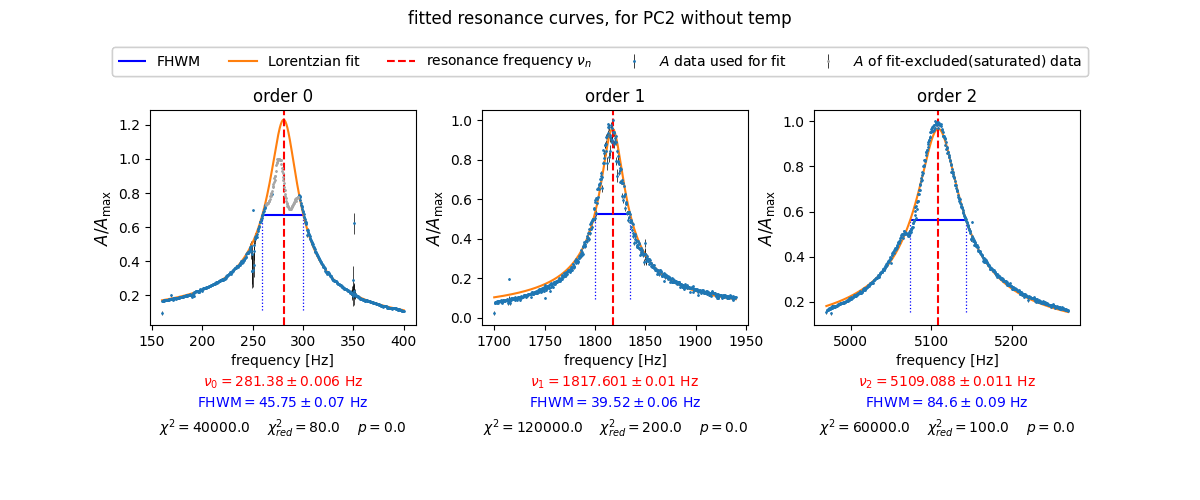

In [ ]:
# all modes fitted
Test_PC2.makeplot(whichplots=[0,1,2],freq_min=None,freq_max=None,fit=True,fitorder=True,savefig=None)


Only the chosen plots are shown: [0, 1, 2]


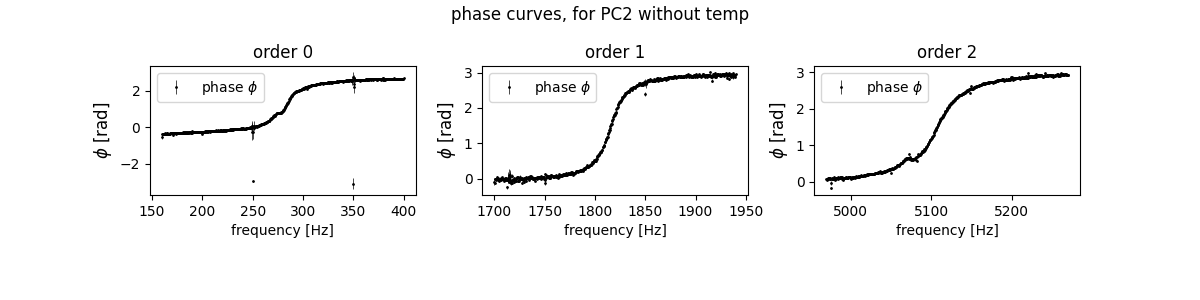

In [25]:
# all phases
Test_PC2.makeplot(whichplots=[0,1,2],freq_min=None,freq_max=None,fit=None,fitorder=None,phase=True,savefig=None)


Only the chosen plots are shown: [0, 1, 2]
\nu_R aus Nulldurchgang = \qty{287.0(0.5)}{\hertz}
--- Fit-Ergebnisse ---
 f_0 = \qty{361350(160)}{\volt}
\nu_{0_0} = \qty{281.380(0.006)}{\hertz}
\nu_{R_0} = \qty{280.757(0.007)}{\hertz}
\gamma = \qty{166.33(0.22)}{\rad\per\s}
y_0 = \qty{0.00000(0.00009)}{\volt}
Q =\num{10.629(0.015)}
Q_{\text{graf}}=\num{11.89(0.18)}
S[\sigma]=\num{7}
Q_{Y,\text{ graf}}=\num{5.89(0.07)}
S_Y[\sigma]=\num{70}\sigma
0.4000000000000341
FHWM_graf=\qty{40.9(0.6)}{\hertz}
FHWM_calc=\qty{45.75(0.07)}{\hertz}
S[\sigma]=\num{70}\sigma
------
Datenpunkte N = 520
Parameterzahl = 4
\mathrm{dof} = 516
\chi_2 = \num{40000}
\mathrm{red} \chi_2 = \num{80}
Fitwahrscheinlichkeit p = \qty{0.0}{\\percent}
---- 
Gefittete Eigenfrequenz: siehe oben
Nächstgelegene Messfrequenz: 281.402
A an diesem Punkt: 0.8358103282226016
Delta A: 0.0009066003371668192
Signal-Rauschverhältnis: 900.0
 
\nu_R aus Nulldurchgang = \qty{1816.2(0.5)}{\hertz}
--- Fit-Ergebnisse ---
 f_0 = \qty{1551700(13

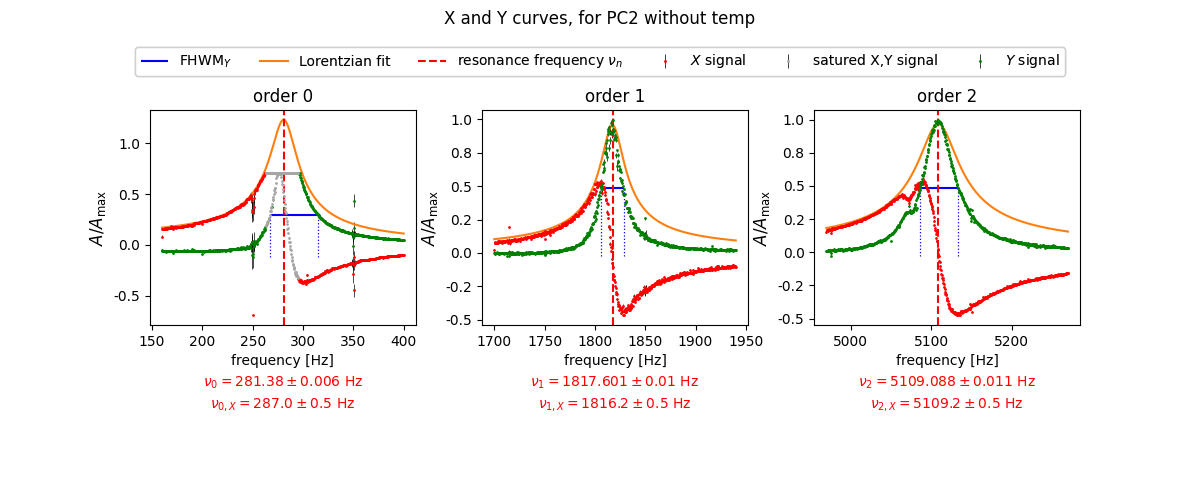

In [26]:
# X,Y plus fit
Test_PC2.makeplot(whichplots=[0,1,2],freq_min=None,freq_max=None,fit=True,fitorder=True,xy_switch=True,phase=None,residuals=None,savefig=None)


In [ ]:
# raw X,Y data
Test_PC2.makeplot(whichplots=[0],freq_min=None,freq_max=None,fit=None,fitorder=None,xy_switch=True,savefig=None)

Only the chosen plots are shown: [0, 1, 2]
--- Fit-Ergebnisse ---
 f_0 = \qty{361350(160)}{\volt}
\nu_{0_0} = \qty{281.380(0.006)}{\hertz}
\nu_{R_0} = \qty{280.757(0.007)}{\hertz}
\gamma = \qty{166.33(0.22)}{\rad\per\s}
y_0 = \qty{0.00000(0.00009)}{\volt}
Q =\num{10.629(0.015)}
Q_{\text{graf}}=\num{11.89(0.18)}
S[\sigma]=\num{7}
0.4000000000000341
FHWM_graf=\qty{40.9(0.6)}{\hertz}
FHWM_calc=\qty{45.75(0.07)}{\hertz}
S[\sigma]=\num{70}\sigma
------
Datenpunkte N = 520
Parameterzahl = 4
\mathrm{dof} = 516
\chi_2 = \num{40000}
\mathrm{red} \chi_2 = \num{80}
Fitwahrscheinlichkeit p = \qty{0.0}{\\percent}
---- 
Gefittete Eigenfrequenz: siehe oben
Nächstgelegene Messfrequenz: 281.402
A an diesem Punkt: 0.8358103282226016
Delta A: 0.0009066003371668192
Signal-Rauschverhältnis: 900.0
 
--- Fit-Ergebnisse ---
 f_0 = \qty{1551700(1300)}{\volt}
\nu_{0_1} = \qty{1817.601(0.010)}{\hertz}
\nu_{R_1} = \qty{1817.529(0.011)}{\hertz}
\gamma = \qty{143.37(0.18)}{\rad\per\s}
y_0 = \qty{0.00842(0.00013)}{\

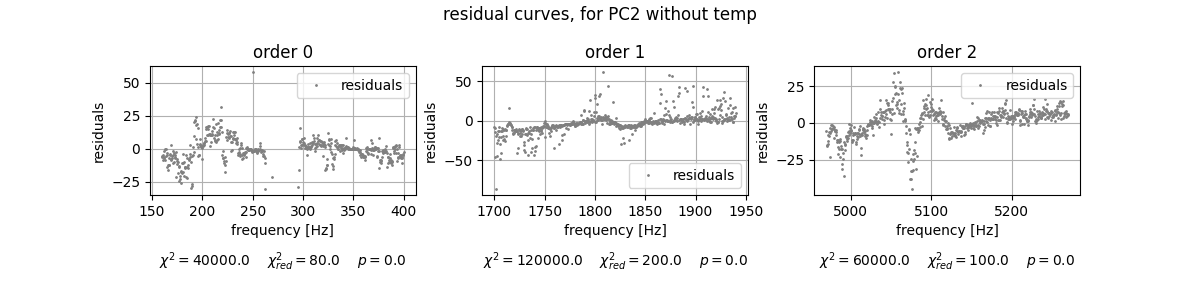

In [28]:
# all residuals, fitorder needs to be True.
Test_PC2.makeplot(whichplots=[0,1,2],freq_min=None,freq_max=None,fit=None,fitorder=True,xy_switch=None,phase=None,residuals=True,savefig=None)


# stacked temp plots and temp development

PC2

[37 40 43 46 49 52 55 58]
Requested files: [37 40 43 46 49 52 55 58]
Of the given files, these were found: [37 40 43 46 49 52 55 58]
Your entry was correct, all given files were found.
Only the chosen plots are shown: [37 40 43 46 49 52 55 58]


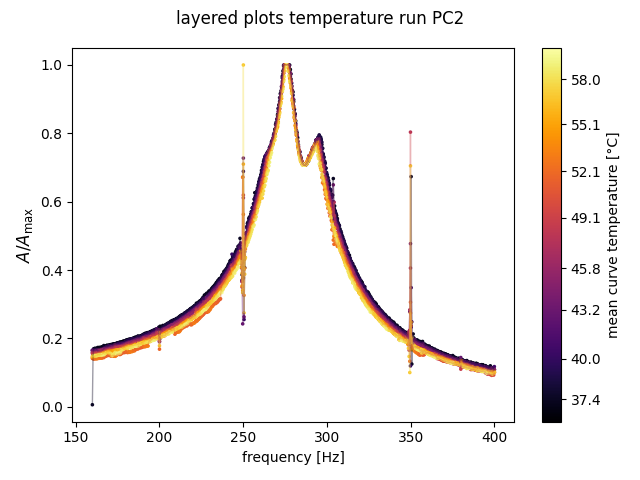

In [35]:

all_numbers=np.arange(37,61,3)
print(all_numbers)
Temp=Layered_Plot("Messungen/PC2/WithTemp/final_TempFreq",plottitle="temperature run PC2",filenumbers=all_numbers)
Temp.layered_plot(whichplots=all_numbers,fit=None,savefig=None)

Only the chosen plots are shown: [37 40 43 46 49 52 55 58]
temp interval: 37.43+0.86-0.44
temp interval: 40.04+1.36-1.24
temp interval: 43.20+1.57-1.80
temp interval: 45.85+1.51-1.86
temp interval: 49.08+1.39-1.20
temp interval: 52.08+0.99-1.61
temp interval: 55.11+1.32-1.27
temp interval: 58.01+1.54-1.05


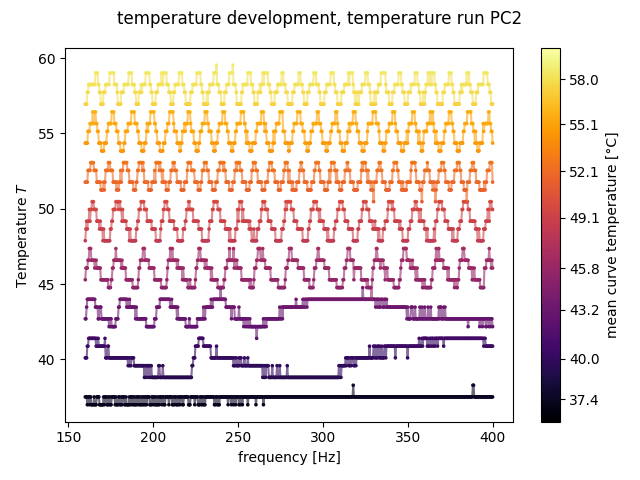

In [36]:
# development
Temp.layered_plot(whichplots=all_numbers,fit=None,plot_type='temperature',savefig=True)

PC1

In [ ]:
all_numbers=np.arange(42,60,2)
print(all_numbers)
Temp=Layered_Plot("Messungen/PC1/PC1_final_WithTemp/TempFreq",plottitle="temperature run PC1",filenumbers=all_numbers)
Temp.layered_plot(freq_min=248,freq_max=252,fit=None,savefig=None)

In [ ]:
# development by adding the plot_type='temperature' option
Temp.layered_plot(whichplots=all_numbers,fit=None,plot_type='temperature',savefig=None)

# PC1 res 0,1,2

Only the chosen plots are shown: [1]
--- Fit-Ergebnisse ---
 f_0 = \qty{2700(220)}{\volt}
\nu_{0_1} = \qty{1649.7397(0.0021)}{\hertz}
\nu_{R_1} = \qty{1649.7397(0.0022)}{\hertz}
\gamma = \qty{0.26(0.04)}{\rad\per\s}
y_0 = \qty{0.055(0.005)}{\volt}
Q =\num{40000(7000)}
Q_{\text{graf}}=\num{41000(24000)}
S[\sigma]=\num{0.04}
0.023999999998750354
FHWM_graf=\qty{0.07(0.04)}{\hertz}
FHWM_calc=\qty{0.071(0.013)}{\hertz}
S[\sigma]=\num{0.08}\sigma
------
Datenpunkte N = 104
Parameterzahl = 4
\mathrm{dof} = 100
\chi_2 = \num{100}
\mathrm{red} \chi_2 = \num{1.0}
Fitwahrscheinlichkeit p = \qty{48.1192}{\\percent}
---- 
Gefittete Eigenfrequenz: siehe oben
Nächstgelegene Messfrequenz: 1649.748
A an diesem Punkt: 0.8889917360830873
Delta A: 0.06756067681500091
Signal-Rauschverhältnis: 13.0
 


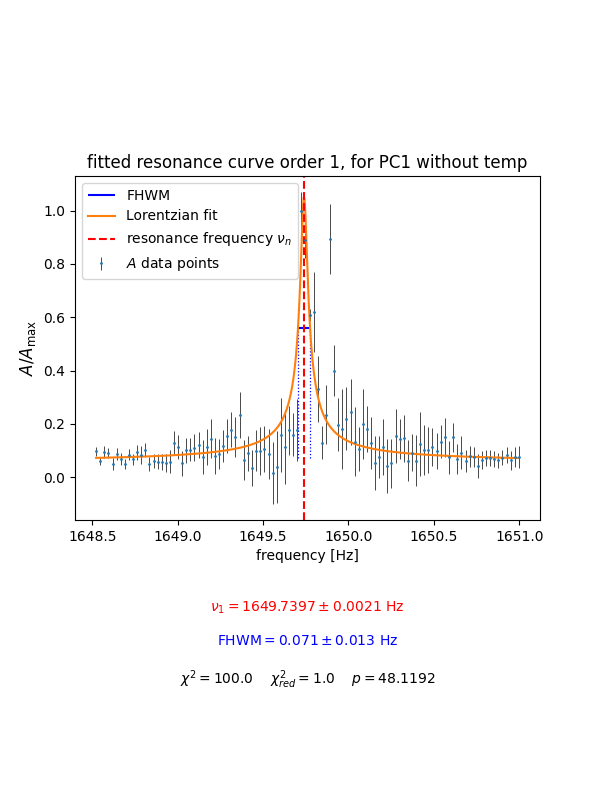

Only the chosen plots are shown: [2]


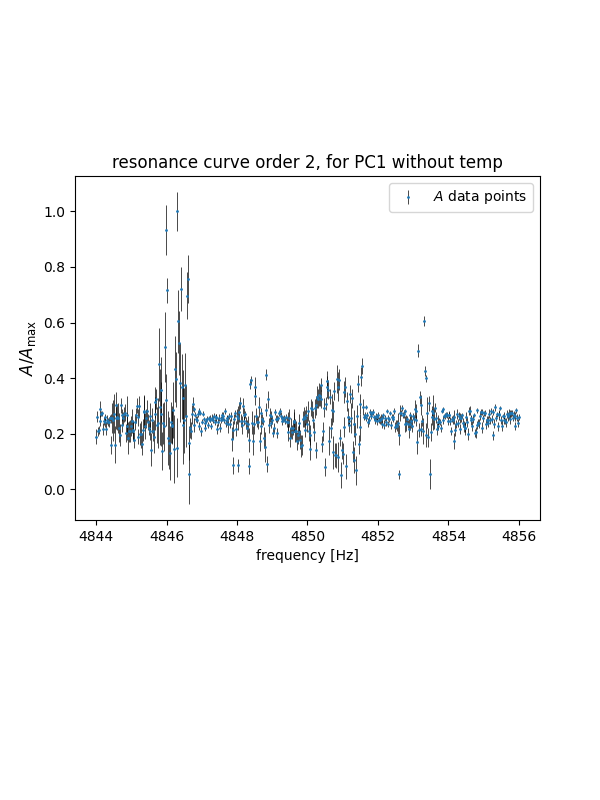

In [19]:
# Gesamte Frequenzbreite auf einen Blick erfassen
### = done

# Test_PC1.makeplot(whichplots=[0,1,2],freq_min=[248,1647.5,4844],freq_max=[252,1655.0,4855.0],savefig=None) # fitoder=True wenn 0,1,2 gefitted
# Test_PC1.makeplot(whichplots=[0],freq_min=248,freq_max=252,fit=True,fitorder=True,savefig=None)
### Test_PC1.makeplot(whichplots=[0],freq_min=248,freq_max=252,fit=None,fitorder=None,residuals=True,savefig=None)
### Test_PC1.makeplot(whichplots=[0],freq_min=248,freq_max=252,fit=True,fitorder=True,xy_switch=True,savefig=True)
### Test_PC1.makeplot(whichplots=[0],freq_min=248,freq_max=252,fit=None,fitorder=None,phase=True,savefig=True)

Test_PC1.makeplot(whichplots=[1],freq_min=1648.5,freq_max=1651,fit=True,fitorder=True,savefig=None)



Test_PC1.makeplot(whichplots=[2],freq_min=None,freq_max=None,fit=None,fitorder=True,savefig=None)
# Test_PC1.save_fig(whichplots=[2],freq_min=None,freq_max=None,fit=None,fitorder=True)
